In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns

import joblib

In [2]:
df = pd.read_csv("balanced_mq2_dataset.csv")

flag_columns = [
    "Normal_Flag",
    "Warning_Flag",
    "Critical_Flag"
]

# Check that each record has exactly one active flag
assert (df[flag_columns].sum(axis=1) == 1).all()

# Convert three flags into one target column
df["Condition"] = df[flag_columns].idxmax(axis=1)

df["Condition"] = df["Condition"].map({
    "Normal_Flag": "Normal",
    "Warning_Flag": "Warning",
    "Critical_Flag": "Critical"
})
# Input features
X = df[["MQ2", "TEMP", "HUMIDITY"]]

# Target variable
y = df["Condition"]


In [3]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [4]:
# Define the models to be evaluated
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ]),

    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

In [5]:
# Train the model
trained_models = {}
predictions = {}

for name, pipeline in models.items():

    # Training
    pipeline.fit(X_train, y_train)

    # Prediction
    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred

    print(name, "completed")

Logistic Regression completed
Decision Tree completed
Random Forest completed


In [6]:
#Calculate performance metrics for each model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, y_pred in predictions.items():

    results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_test, y_pred
        ),

        "Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.9533     0.9591  0.9533     0.954
1        Decision Tree    1.0000     1.0000  1.0000     1.000
2        Random Forest    1.0000     1.0000  1.0000     1.000


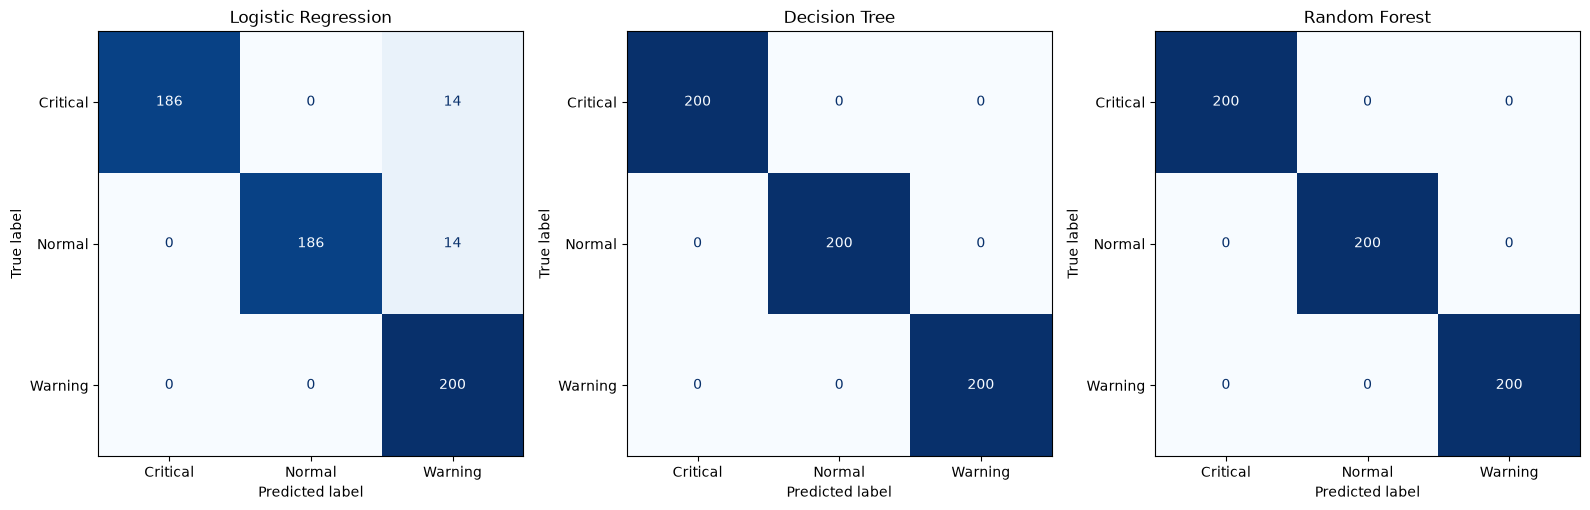

In [7]:
#Generating confusion matrices for each model
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, y_pred) in zip(
    axes, predictions.items()
):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["Critical", "Normal", "Warning"],
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [8]:
#Detailed classification report for each model
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():

    print("\n", "=" * 40)
    print(name)
    print("=" * 40)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

    Critical       1.00      0.93      0.96       200
      Normal       1.00      0.93      0.96       200
     Warning       0.88      1.00      0.93       200

    accuracy                           0.95       600
   macro avg       0.96      0.95      0.95       600
weighted avg       0.96      0.95      0.95       600


Decision Tree
              precision    recall  f1-score   support

    Critical       1.00      1.00      1.00       200
      Normal       1.00      1.00      1.00       200
     Warning       1.00      1.00      1.00       200

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600


Random Forest
              precision    recall  f1-score   support

    Critical       1.00      1.00      1.00       200
      Normal       1.00      1.00      1.00       200
     Warning       1.00 

In [9]:
#Select the best model based on F1 Score
best_model_name = comparison_df.loc[
    comparison_df["F1 Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Decision Tree


In [10]:
#Save the best performing model
joblib.dump(best_model,"new_model.pkl"
)
print("Model saved successfully!")

Model saved successfully!


In [11]:
#Test the saved model
# Load saved model
model = joblib.load("new_model.pkl")

# Test sensor readings
test_data = pd.DataFrame([
    {"MQ2": 28, "TEMP": 25, "HUMIDITY": 45},
    {"MQ2": 5, "TEMP": 36, "HUMIDITY": 70},
    {"MQ2": 18, "TEMP": 47, "HUMIDITY": 75}
])

# Predict
predictions = model.predict(test_data)

# Get probabilities
probabilities = model.predict_proba(test_data)

# Display results
for i in range(len(test_data)):

    print("\nSensor Reading:")
    print(test_data.iloc[i].to_dict())

    print("Predicted Status:", predictions[i])

    print("Confidence:", round(
        max(probabilities[i]) * 100, 2
    ), "%")


Sensor Reading:
{'MQ2': 28, 'TEMP': 25, 'HUMIDITY': 45}
Predicted Status: Critical
Confidence: 100.0 %

Sensor Reading:
{'MQ2': 5, 'TEMP': 36, 'HUMIDITY': 70}
Predicted Status: Normal
Confidence: 100.0 %

Sensor Reading:
{'MQ2': 18, 'TEMP': 47, 'HUMIDITY': 75}
Predicted Status: Warning
Confidence: 100.0 %
